In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
halogen_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(halogen_dir)
df = pd.read_csv('hbond_EDA.csv')
# df = raw_df.query('TOTAL < 0')
df.shape

(4977, 43)

In [2]:
print(len(df.query('TOTAL > 0')))  # highest TOTAL = 27.8550
print(len(df.query('TOTAL < 0'))) # lowest TOTAL = -52.9949

394
4583


In [3]:
labels = ['Neutral-Neutral', 'Neutral-Charged', 'Charged-Charged']

def split_sc(df):
    dfList = []
    dfList.append(df.query('charge0 == 0 & charge1 == 0 & TOTAL < 0'))
    dfList.append(df.query('(charge0 == 0 & charge1 != 0) | (charge0 != 0 & charge1 == 0)'))
    dfList.append(df.query('(charge0 < 0 & charge1 > 0) | (charge0 > 0 & charge1 < 0)'))
    return dfList

In [4]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_27926/4189223964.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


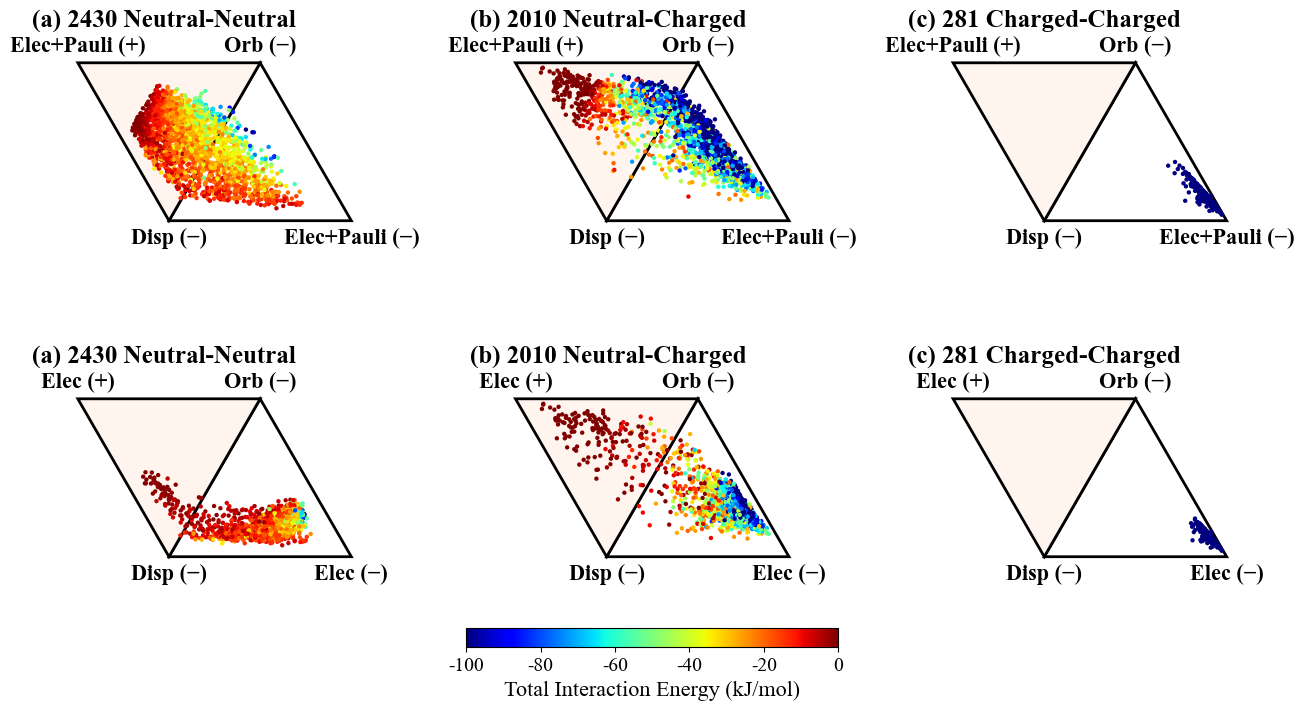

In [19]:
dfs = split_sc(df)
cmap_range = [-100, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
sc = plot('ternary', (labels[0], 'a', 'frz_orb_disp'), dfs[0], axes[0, 0], cmap_range)
plot('ternary', (labels[1], 'b', 'frz_orb_disp'), dfs[1], axes[0, 1], cmap_range)
plot('ternary', (labels[2], 'c', 'frz_orb_disp'), dfs[2], axes[0, 2], cmap_range)
plot('ternary', (labels[0], 'a', 'elec_orb_disp'), dfs[0], axes[1, 0], cmap_range)
plot('ternary', (labels[1], 'b', 'elec_orb_disp'), dfs[1], axes[1, 1], cmap_range)
plot('ternary', (labels[2], 'c', 'elec_orb_disp'), dfs[2], axes[1, 2], cmap_range)


cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary_presentation.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_27926/119671736.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


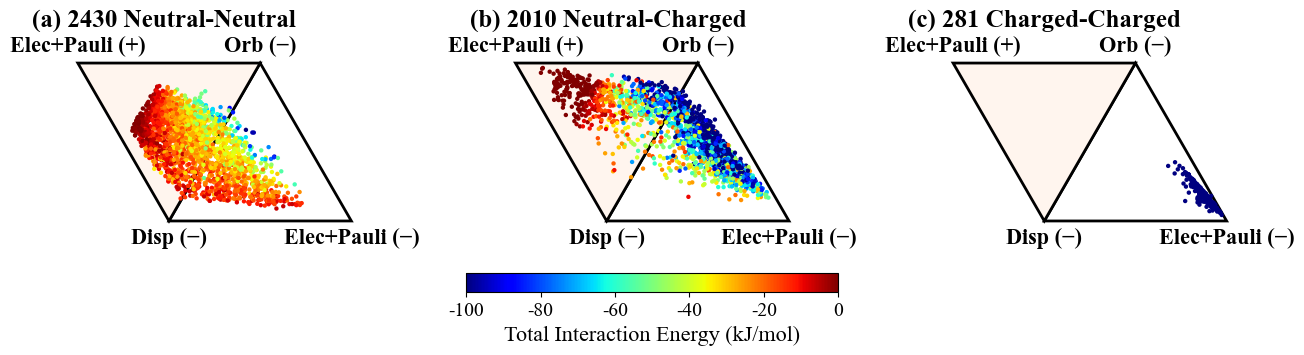

In [5]:
dfs = split_sc(df)
cmap_range = [-100, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), dfs[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary_frz_orb_disp.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_27926/380416956.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


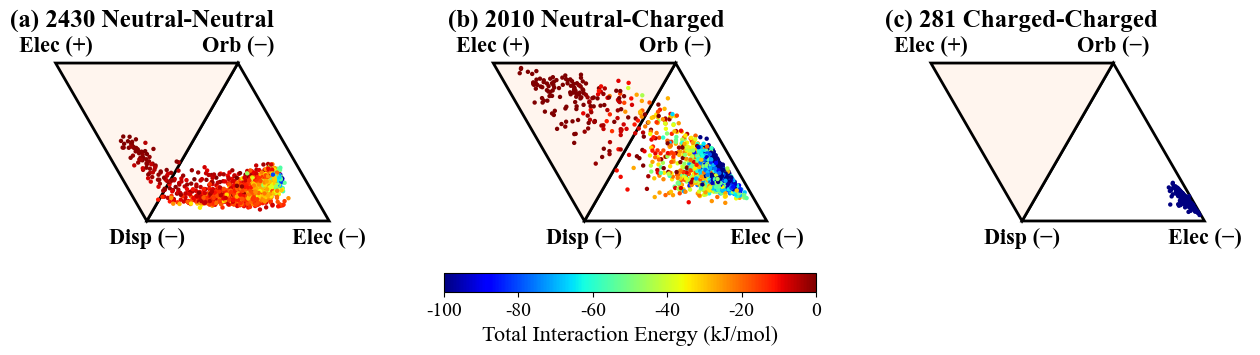

In [6]:
type = 'elec_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), dfs[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary_elec_orb_disp.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_27926/2090594802.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


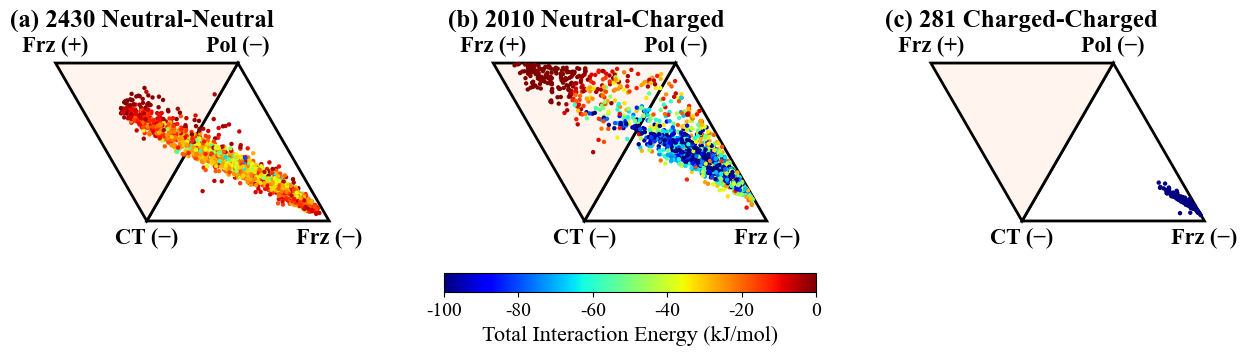

In [7]:
type = 'frz_pol_ct'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), dfs[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig('Visualizations/ternary_frz_pol_ct.png')

# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: list(map(len, dfs))
len: list(map(len, dfs))


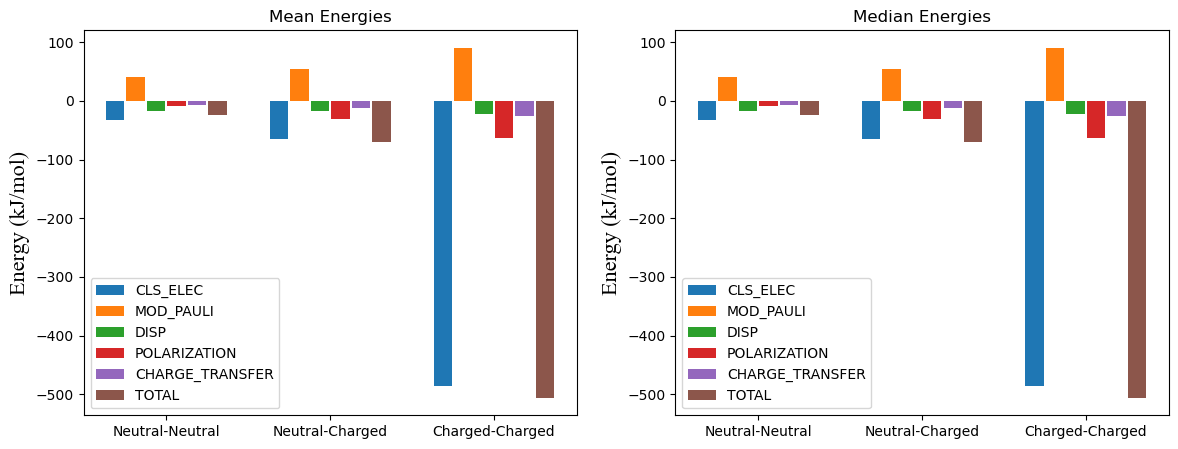

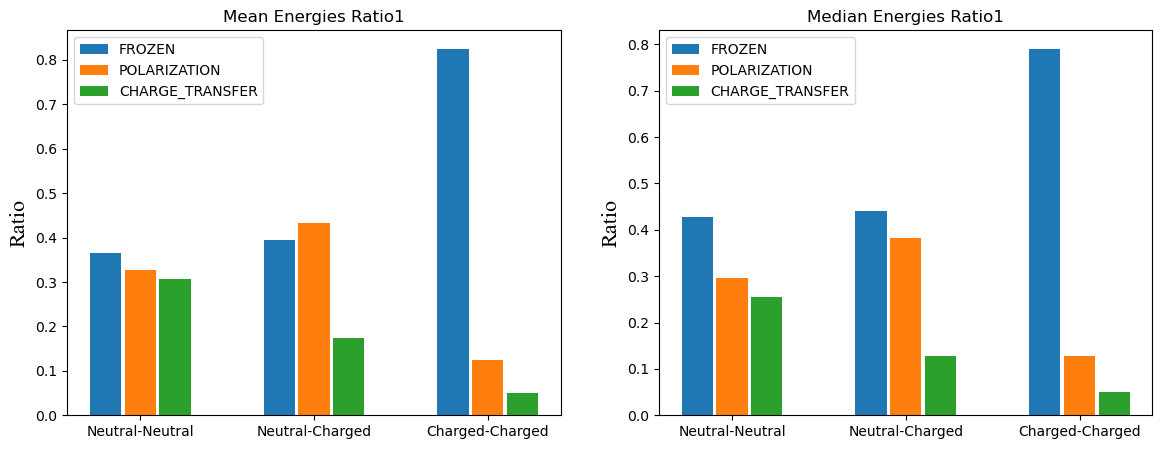

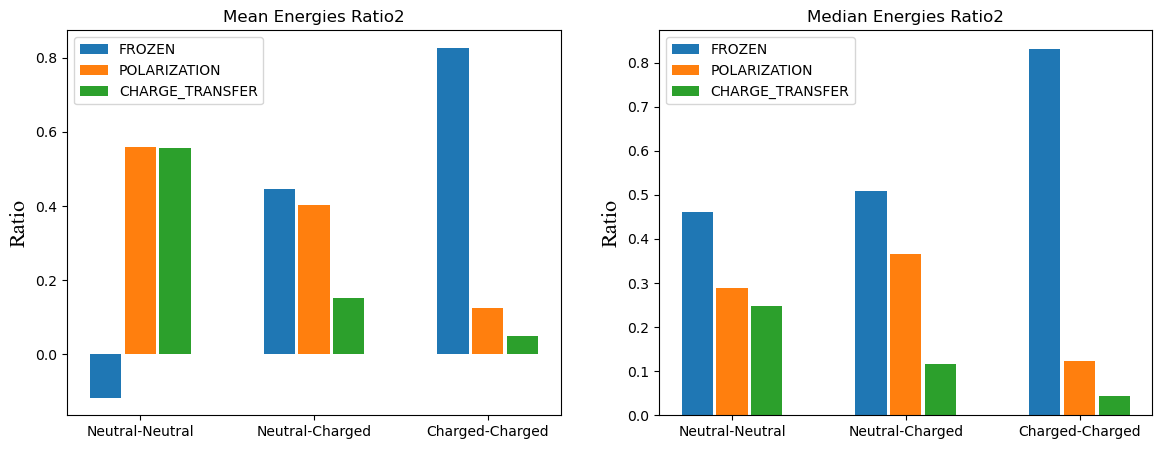

In [12]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_sc(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all.png')

# items = [
#     'FROZEN', 
#     'CLS_ELEC', 
#     # 'MOD_PAULI', 
#     # 'DISP', 
#     'PAULI+DISP', 
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     'TOTAL'
# ]
# dfs = split_sc(df)

# print(f'len: list(map(len, dfs))')

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plot('bar', (labels, items), dfs, axes[0])
# axes[0].set_title('Mean Energies')
# plot('bar', (labels, items), dfs, axes[1], median=True)
# axes[1].set_title('Median Energies')
# plt.savefig('Visualizations/bar_Energy_pauli+disp.png')


# items = [
#     'FROZEN', 
#     'CLS_ELEC', 
#     # 'MOD_PAULI', 
#     # 'DISP', 
#     'PAULI+DISP',
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     # 'TOTAL'
# ]

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plot('bar', (labels, items), dfs, axes[0], ratio1=True)
# axes[0].set_title('Mean Energies Ratio1')
# plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
# axes[1].set_title('Median Energies Ratio1')
# plt.savefig('Visualizations/bar_ratio1_all_pauli+disp.png')

# items = [
#     'FROZEN', 
#     'CLS_ELEC', 
#     # 'MOD_PAULI', 
#     # 'DISP', 
#     'PAULI+DISP',
#     'POLARIZATION', 
#     'CHARGE_TRANSFER', 
#     # 'TOTAL'
# ] 

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plot('bar', (labels, items), dfs, axes[0], ratio2=True)
# axes[0].set_title('Mean Energies Ratio2')
# plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
# axes[1].set_title('Median Energies Ratio2')
# plt.savefig('Visualizations/bar_ratio2_all_pauli+disp.png')

items = [
    'FROZEN', 
    # 'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]
dfs = split_sc(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio1')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio1')
plt.savefig('Visualizations/bar_ratio1_FRZ_POL_CT.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio2')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio2')
plt.savefig('Visualizations/bar_ratio2_FRZ_POL_CT.png')

len: list(map(len, dfs))


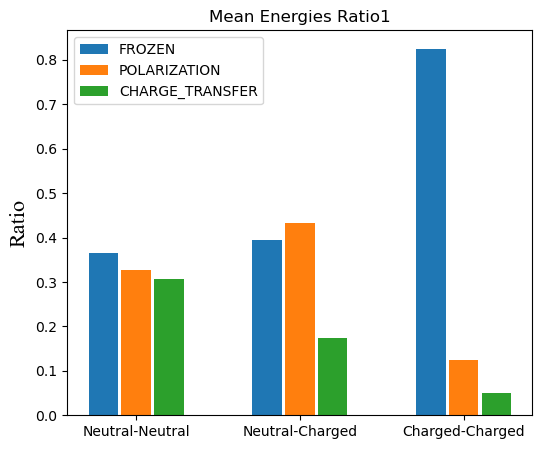

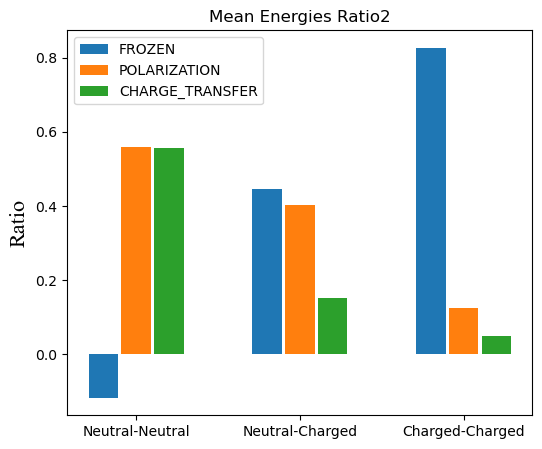

In [17]:
items = [
    'FROZEN', 
    # 'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]
dfs = split_sc(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(figsize=(6, 5))
plot('bar', (labels, items), dfs, axes, ratio1=True)
axes.set_title('Mean Energies Ratio1')
plt.savefig('Visualizations/bar_ratio1_FRZ_POL_CT_mean.png')

fig, axes = plt.subplots(figsize=(6, 5))
plot('bar', (labels, items), dfs, axes, ratio2=True)
axes.set_title('Mean Energies Ratio2')
plt.savefig('Visualizations/bar_ratio2_FRZ_POL_CT_mean.png')